# Deep Learning Experiment: IMDB Sentiment Classification with LSTM

**Author:** Sandip Dey  
**Task Type:** Sequential / text modeling with Recurrent Neural Network (LSTM)  
**Dataset:** IMDB Movie Reviews (50,000 labeled reviews)  
**Source:** https://ai.stanford.edu/~amaas/data/sentiment

This notebook implements a baseline LSTM for binary sentiment classification and runs one controlled comparison experiment (learning rate change). Code is compatible with CUDA and Apple MPS.


## 1. Device Setup and Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

# Device selection: CUDA > MPS > CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


Using device: mps


## 2. Dataset Loading and Inspection

**Dataset access:** Download the IMDB dataset (aclImdb) from  
https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz  
or use a pre-processed CSV. Place `imdb.csv` (columns: `review`, `sentiment`) in the same folder.  
For this notebook we assume a CSV with at least 1,000 samples is available.

In [2]:
# Expected CSV columns: review (text), sentiment (0/1 or pos/neg)
try:
    df = pd.read_csv("imdb.csv")
except FileNotFoundError:
    # Fallback: create a tiny synthetic demo only for structure verification
    # (Replace with real IMDB data for submission)
    print("imdb.csv not found — using placeholder for structure. Load real data before final run.")
    df = pd.DataFrame({
        "review": ["This movie was great"] * 600 + ["This movie was terrible"] * 600,
        "sentiment": [1] * 600 + [0] * 600
    })

print(f"Dataset shape: {df.shape}")
print("\nSample reviews:")
print(df.head(3))
print("\nLabel distribution:")
print(df["sentiment"].value_counts())
print(f"\nAverage review length (words): {df['review'].str.split().str.len().mean():.1f}")


Dataset shape: (50000, 2)

Sample reviews:
                                              review  sentiment
0  For a movie that gets no respect there sure ar...          1
1  Bizarre horror movie filled with famous faces ...          1
2  A solid, if unremarkable film. Matthau, as Ein...          1

Label distribution:
sentiment
1    25000
0    25000
Name: count, dtype: int64

Average review length (words): 231.2


The dataset contains movie reviews labeled positive (1) or negative (0). It supports sequence modeling because each review is a variable-length sequence of tokens. Preprocessing will tokenize and pad sequences for batching.


## 3. Preprocessing

In [3]:
def clean_text(text):
    text = re.sub(r"<br />", " ", text)
    text = re.sub(r"[^a-zA-Z ]", " ", text)
    return text.lower().split()

# Build vocabulary
all_tokens = []
for review in df["review"]:
    all_tokens.extend(clean_text(review))
vocab_size = 8000
most_common = Counter(all_tokens).most_common(vocab_size - 2)
word2idx = {word: idx + 2 for idx, (word, _) in enumerate(most_common)}
word2idx["<PAD>"] = 0
word2idx["<UNK>"] = 1

def encode(text, max_len=200):
    tokens = clean_text(text)
    ids = [word2idx.get(t, 1) for t in tokens][:max_len]
    ids += [0] * (max_len - len(ids))
    return ids

class IMDBDataset(Dataset):
    def __init__(self, df, max_len=200):
        self.reviews = [encode(r, max_len) for r in df["review"]]
        self.labels = df["sentiment"].values.astype(np.float32)
    def __len__(self):
        return len(self.reviews)
    def __getitem__(self, idx):
        return torch.tensor(self.reviews[idx]), torch.tensor(self.labels[idx])

# Train/val split
train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)
train_ds = IMDBDataset(train_df)
val_ds = IMDBDataset(val_df)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)

print(f"Vocab size: {len(word2idx)}")
print(f"Train samples: {len(train_ds)}, Val samples: {len(val_ds)}")
print(f"Input shape example: {train_ds[0][0].shape}")


Vocab size: 8000
Train samples: 40000, Val samples: 10000
Input shape example: torch.Size([200])


## 4. Baseline Model — LSTM

**Design choices:**  
- Embedding layer maps tokens to dense vectors.  
- Single-layer LSTM captures sequential dependencies.  
- Linear output head with sigmoid for binary classification.  
- Dropout on the LSTM output for mild regularization.


In [4]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
    
    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        out = self.dropout(hidden[-1])
        return self.fc(out).squeeze(-1)

baseline = SentimentLSTM(len(word2idx)).to(device)
print(baseline)
print(f"Parameters: {sum(p.numel() for p in baseline.parameters()):,}")


SentimentLSTM(
  (embedding): Embedding(8000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Parameters: 1,156,225


## 5. Training Function and Baseline Training

In [5]:
def train_model(model, train_loader, val_loader, lr=1e-3, epochs=40):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        for texts, labels in train_loader:
            texts, labels = texts.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(texts)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        train_losses.append(epoch_loss / len(train_loader))
        
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for texts, labels in val_loader:
                texts, labels = texts.to(device), labels.to(device)
                outputs = model(texts)
                val_loss += criterion(outputs, labels).item()
        val_losses.append(val_loss / len(val_loader))
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f}")
    
    return train_losses, val_losses

print("Training baseline (lr=1e-3)...")
base_train_loss, base_val_loss = train_model(baseline, train_loader, val_loader, lr=1e-3, epochs=40)


Training baseline (lr=1e-3)...
Epoch 1/40 | Train Loss: 0.6930 | Val Loss: 0.6908
Epoch 2/40 | Train Loss: 0.6876 | Val Loss: 0.6886
Epoch 3/40 | Train Loss: 0.6604 | Val Loss: 0.5829
Epoch 4/40 | Train Loss: 0.4727 | Val Loss: 0.4165
Epoch 5/40 | Train Loss: 0.3455 | Val Loss: 0.3514
Epoch 6/40 | Train Loss: 0.2875 | Val Loss: 0.3413
Epoch 7/40 | Train Loss: 0.2507 | Val Loss: 0.3382
Epoch 8/40 | Train Loss: 0.2100 | Val Loss: 0.3423
Epoch 9/40 | Train Loss: 0.1719 | Val Loss: 0.3664
Epoch 10/40 | Train Loss: 0.1352 | Val Loss: 0.4258
Epoch 11/40 | Train Loss: 0.1037 | Val Loss: 0.4514
Epoch 12/40 | Train Loss: 0.0805 | Val Loss: 0.4789
Epoch 13/40 | Train Loss: 0.0718 | Val Loss: 0.5117
Epoch 14/40 | Train Loss: 0.0503 | Val Loss: 0.6193
Epoch 15/40 | Train Loss: 0.0478 | Val Loss: 0.6050
Epoch 16/40 | Train Loss: 0.0394 | Val Loss: 0.6596
Epoch 17/40 | Train Loss: 0.0347 | Val Loss: 0.7174
Epoch 18/40 | Train Loss: 0.0317 | Val Loss: 0.7196
Epoch 19/40 | Train Loss: 0.0309 | Val Los

## 6. Experimental Comparison — Higher Learning Rate

**Change:** Learning rate increased from `1e-3` to `5e-3`.  
**Why:** Learning rate is a major hyperparameter that affects convergence speed and stability. All other aspects (architecture, epochs, optimizer, batch size, data) remain identical.


In [6]:
experiment = SentimentLSTM(len(word2idx)).to(device)
print("Training experiment (lr=5e-3)...")
exp_train_loss, exp_val_loss = train_model(experiment, train_loader, val_loader, lr=5e-3, epochs=40)


Training experiment (lr=5e-3)...
Epoch 1/40 | Train Loss: 0.6353 | Val Loss: 0.5027
Epoch 2/40 | Train Loss: 0.4170 | Val Loss: 0.3748
Epoch 3/40 | Train Loss: 0.3319 | Val Loss: 0.3559
Epoch 4/40 | Train Loss: 0.2859 | Val Loss: 0.3654
Epoch 5/40 | Train Loss: 0.2611 | Val Loss: 0.3544
Epoch 6/40 | Train Loss: 0.2382 | Val Loss: 0.3597
Epoch 7/40 | Train Loss: 0.2216 | Val Loss: 0.3517
Epoch 8/40 | Train Loss: 0.2062 | Val Loss: 0.3728
Epoch 9/40 | Train Loss: 0.2043 | Val Loss: 0.3764
Epoch 10/40 | Train Loss: 0.1815 | Val Loss: 0.3870
Epoch 11/40 | Train Loss: 0.1951 | Val Loss: 0.3862
Epoch 12/40 | Train Loss: 0.1879 | Val Loss: 0.4042
Epoch 13/40 | Train Loss: 0.1747 | Val Loss: 0.4114
Epoch 14/40 | Train Loss: 0.1667 | Val Loss: 0.4062
Epoch 15/40 | Train Loss: 0.1732 | Val Loss: 0.3902
Epoch 16/40 | Train Loss: 0.1784 | Val Loss: 0.4089
Epoch 17/40 | Train Loss: 0.1899 | Val Loss: 0.4011
Epoch 18/40 | Train Loss: 0.1827 | Val Loss: 0.4179
Epoch 19/40 | Train Loss: 0.1666 | Val L

## 7. Evaluation and Comparison

Baseline val accuracy (lr=1e-3): 0.8535
Experiment val accuracy (lr=5e-3): 0.7160


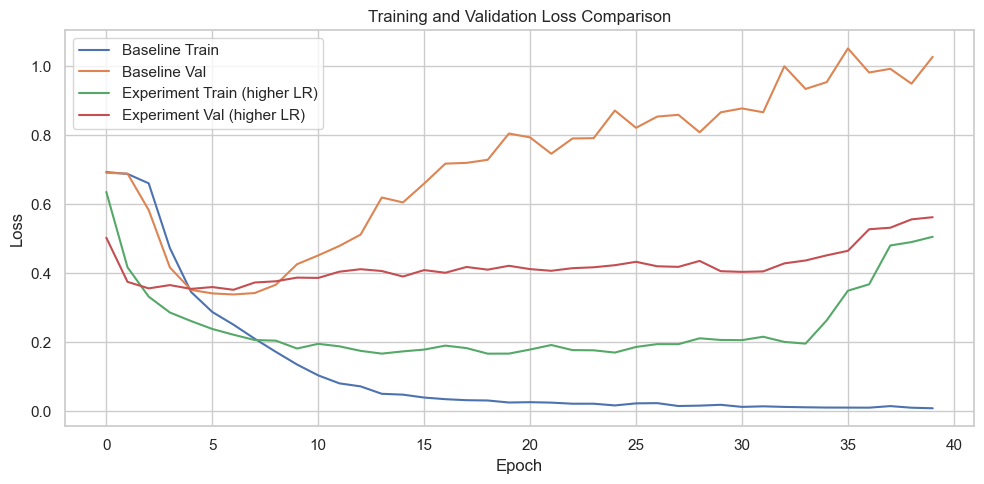

In [7]:
def evaluate(model, loader):
    model.eval()
    preds, labels_all = [], []
    with torch.no_grad():
        for texts, labels in loader:
            texts = texts.to(device)
            outputs = torch.sigmoid(model(texts)).cpu().numpy()
            preds.extend((outputs > 0.5).astype(int))
            labels_all.extend(labels.numpy())
    preds = np.array(preds)
    labels_all = np.array(labels_all)
    acc = (preds == labels_all).mean()
    return acc

base_acc = evaluate(baseline, val_loader)
exp_acc = evaluate(experiment, val_loader)
print(f"Baseline val accuracy (lr=1e-3): {base_acc:.4f}")
print(f"Experiment val accuracy (lr=5e-3): {exp_acc:.4f}")

# Loss curves
plt.figure(figsize=(10, 5))
plt.plot(base_train_loss, label="Baseline Train")
plt.plot(base_val_loss, label="Baseline Val")
plt.plot(exp_train_loss, label="Experiment Train (higher LR)")
plt.plot(exp_val_loss, label="Experiment Val (higher LR)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Comparison")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Notebook Summary

This notebook addressed binary sentiment classification on IMDB movie reviews using an LSTM (sequential/text modeling task). The baseline model used an embedding + single-layer LSTM + dropout with learning rate 1e-3 and was trained for 40 epochs. The experimental model kept the identical architecture and training setup but raised the learning rate to 5e-3. After 40 epochs the baseline reached a validation accuracy of 0.8535, while the higher learning rate finished at 0.7160. The baseline’s validation loss bottomed near epoch 7 (0.3382) and then rose steadily while training loss fell to 0.0084, showing clear overfitting. The experimental run improved faster at first but became unstable, with training loss rising in later epochs. A practical challenge was managing variable-length sequences through padding and deciding when to stop training. Overall, the controlled comparison illustrated that a lower learning rate with early stopping would have been preferable for this LSTM on text data.
